In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [28]:
FILEPATH = "./src/MITBIH-EKG/04015_ekg.csv"

read_file = pd.read_csv(FILEPATH, dtype={'user_id': float}, index_col=0)

C:\Users\Sam\AppData\Local\Temp\ipykernel_10664\3847581573.py:3: DtypeWarning: Columns (3: qrs_annotation, 4: generic_annotation) have mixed types. Specify dtype option on import or set low_memory=False.
  read_file = pd.read_csv(FILEPATH, dtype={'user_id': float}, index_col=0)


In [3]:
read_file

,ECG1,ECG2,qrs_annotation,generic_annotation
0,-0.275,-0.210,NaN,NaN
1,-0.295,-0.200,NaN,NaN
2,-0.310,-0.220,NaN,NaN
3,-0.315,-0.225,NaN,NaN
4,-0.300,-0.215,NaN,NaN
...,...,...,...,...
9205755,-0.765,-1.810,NaN,NaN
9205756,-0.680,-1.560,NaN,NaN
9205757,-0.680,-1.345,NaN,NaN
9205758,-0.670,-1.230,NaN,NaN


<Axes: >

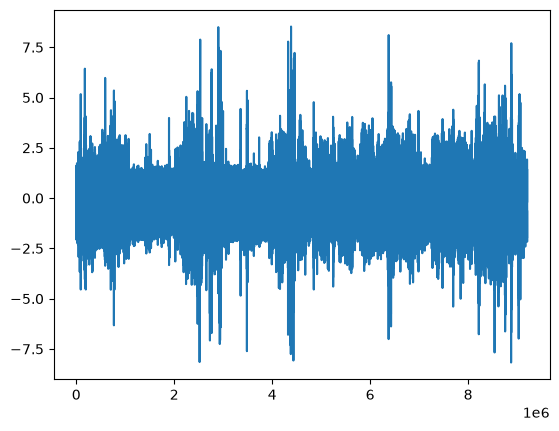

In [4]:
read_file['ECG1'].plot()

<Axes: >

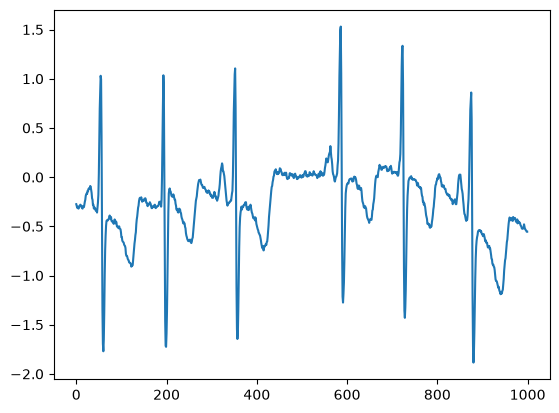

In [5]:
read_file['ECG1'][:1000].plot()

# QRS & R-peak detection (Pan-Tompkins per TASK_BRIEF note 31)

The cells below build stages 1-5 of the AFIB-LITE reference model on top of
the existing ECG load + plot code:

| Stage | What it does                                             |
|-------|----------------------------------------------------------|
| 1     | Bandpass 5-15 Hz (Butterworth, zero-phase)              |
| 2     | 5-point derivative, coefficients `[2,1,0,-1,-2]/8`       |
| 3     | Squaring (pointwise)                                     |
| 4     | Moving-window integrator, 150 ms window                  |
| 5     | Adaptive-threshold R-peak detection (SPKI/NPKI/T1/T2)   |

References:
- Pan & Tompkins 1985, _A real-time QRS detection algorithm_, IEEE TBE 32(3).
- Dash et al. 2009, _Automatic real time detection of atrial fibrillation_.
- TASK_BRIEF.md (project vault, note 31 _Memahami AFIB-LITE_).


## Extended imports + pipeline configuration

In [6]:
# Extra imports for the pipeline
from scipy.signal import butter, filtfilt, convolve, find_peaks

# Pipeline configuration per TASK_BRIEF (note 31)
FS              = 250.0   # Hz, nominal sample rate
BAND_LOW        = 5.0     # Hz, bandpass lower cutoff (stage 1)
BAND_HIGH       = 15.0    # Hz, bandpass upper cutoff (stage 1)
FILT_ORDER      = 4       # Butterworth order
DERIV_COEFFS    = np.array([2.0, 1.0, 0.0, -1.0, -2.0]) / 8.0   # stage 2
MWI_WINDOW_SEC  = 0.150   # stage 4: 150 ms
REFRACTORY_SEC  = 0.200   # stage 5: 200 ms refractory
SEARCH_BACK_F   = 1.66    # stage 5: 1.66 x mean RR

## Stage 1 - Bandpass filter (5-15 Hz)

Zero-phase Butterworth bandpass. Removes baseline wander (<5 Hz) and
mains hum (50 Hz lies well above 15 Hz) while keeping the QRS complex
intact.


In [7]:
def bandpass_filter(x, fs=FS, low=BAND_LOW, high=BAND_HIGH, order=FILT_ORDER):
    """5-15 Hz zero-phase Butterworth bandpass (note 31, stage 1).

    Parameters
    ----------
    x : float ndarray, ECG samples
    fs : Hz, sample rate
    low, high : Hz, passband edges
    order : Butterworth order

    Returns
    -------
    y : float ndarray, same length as x, zero-phase filtered
    """
    nyq = 0.5 * fs
    b, a = butter(order, [low / nyq, high / nyq], btype="band")
    return filtfilt(b, a, x)

### Apply to ECG1 and inspect

Plot the first 5 000 samples (~20 s) so individual QRS complexes are visible.


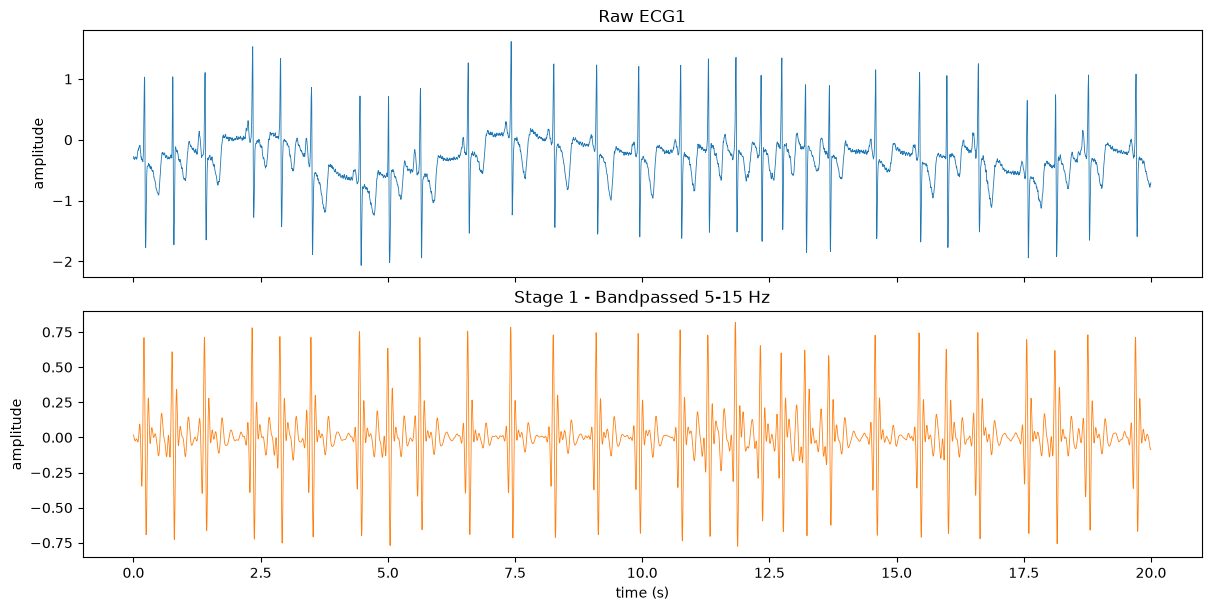

In [9]:
ecg_raw  = read_file['ECG1'].to_numpy(dtype=float)
ecg_filt = bandpass_filter(ecg_raw)

# Short slice for plotting
SLICE = slice(0, 5000)
t = np.arange(SLICE.stop)[SLICE] / FS

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
ax[0].plot(t, ecg_raw[SLICE],  lw=0.6, color='C0')
ax[0].set_title('Raw ECG1')
ax[0].set_ylabel('amplitude')
ax[1].plot(t, ecg_filt[SLICE], lw=0.6, color='C1')
ax[1].set_title('Stage 1 - Bandpassed 5-15 Hz')
ax[1].set_ylabel('amplitude')
ax[1].set_xlabel('time (s)')
plt.show()


## Stage 2 - 5-point derivative

Coefficients `[2, 1, 0, -1, -2] / 8`. Using `'same'` convolution gives a
group delay of (5-1)/2 = 2 samples, as required by the brief.


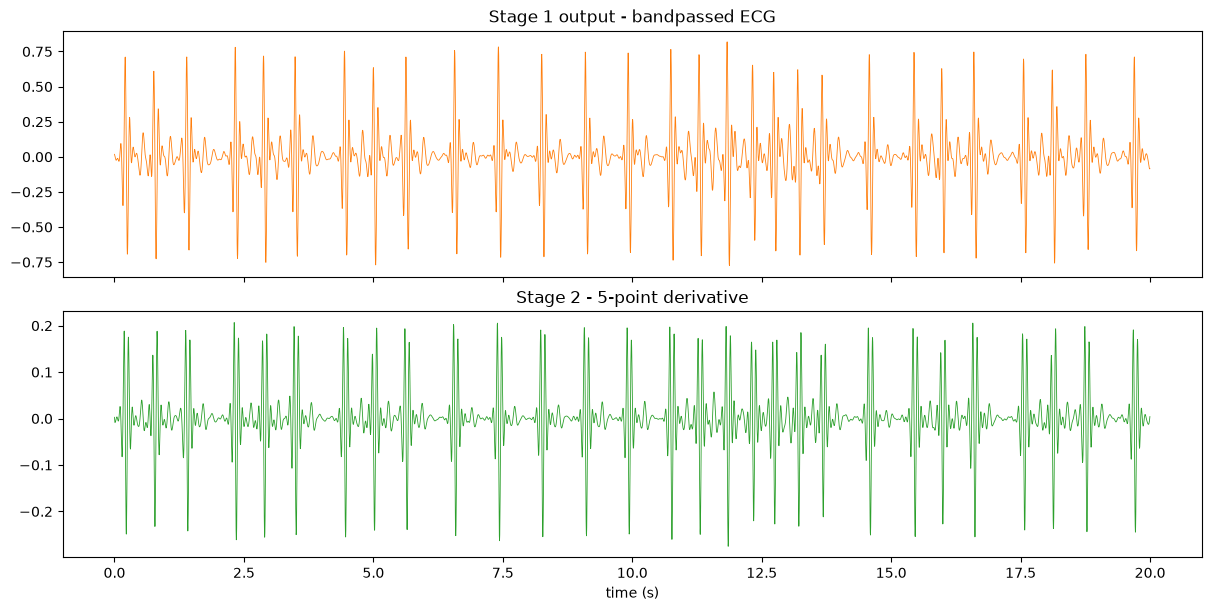

In [10]:
def derivative(x, coeffs=DERIV_COEFFS):
    """5-point derivative with coefficients [2,1,0,-1,-2]/8.

    Group delay = 2 samples (note 31, stage 2).
    """
    return np.convolve(x, coeffs, mode='same')

ecg_deriv = derivative(ecg_filt)

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
ax[0].plot(t, ecg_filt[SLICE],  lw=0.6, color='C1')
ax[0].set_title('Stage 1 output - bandpassed ECG')
ax[1].plot(t, ecg_deriv[SLICE], lw=0.6, color='C2')
ax[1].set_title('Stage 2 - 5-point derivative')
ax[1].set_xlabel('time (s)')
plt.show()


## Stage 3 - Squaring

Pointwise square: makes everything positive and emphasises steep QRS
slopes while suppressing small T-wave energy.


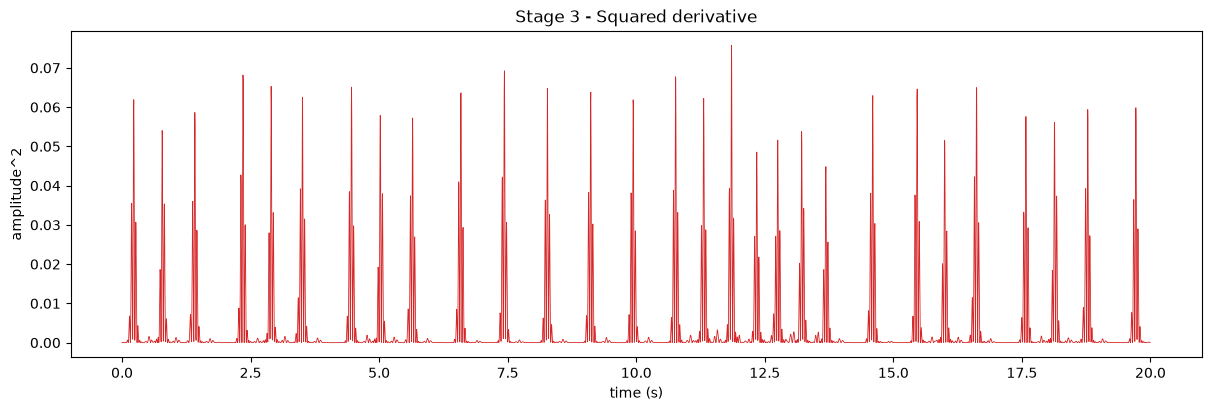

In [11]:
def squarer(x):
    """Pointwise squaring (note 31, stage 3). Output strictly non-negative."""
    return np.asarray(x, dtype=float) ** 2

ecg_sq = squarer(ecg_deriv)

fig, ax = plt.subplots(1, 1, figsize=(12, 4), constrained_layout=True)
ax.plot(t, ecg_sq[SLICE], lw=0.6, color='C3')
ax.set_title('Stage 3 - Squared derivative')
ax.set_xlabel('time (s)')
ax.set_ylabel('amplitude^2')
plt.show()


## Stage 4 - Moving-window integrator (150 ms)

Running average over a 150 ms window. At 250 Hz that is 37.5 samples;
we use `round(0.150 * 250) = 38` here. The production model alternates
37/38 to hit exactly 150 ms on average (see trap #1 in TASK_BRIEF).


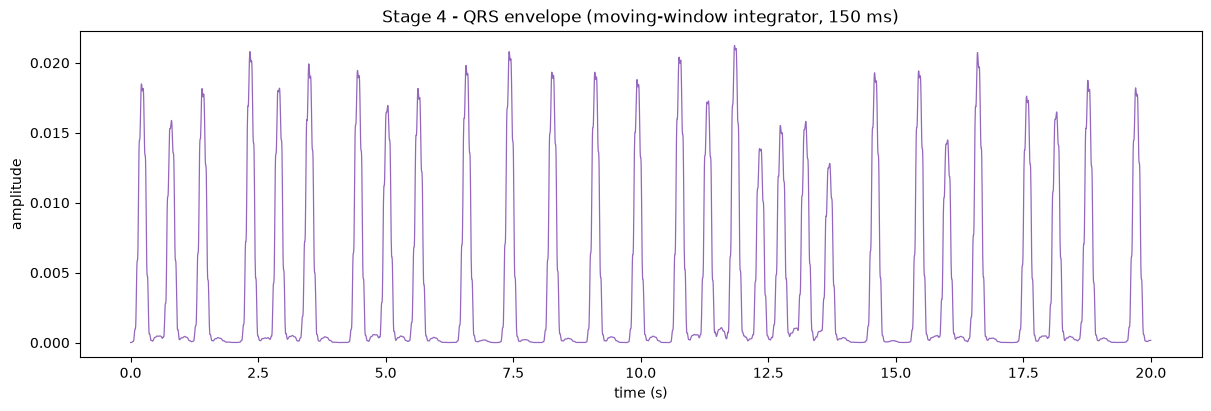

In [12]:
def moving_window_integrator(x, fs=FS, window_sec=MWI_WINDOW_SEC):
    """Running average over a 150 ms window (note 31, stage 4).

    Parameters
    ----------
    x : float ndarray, squared derivative
    fs : Hz
    window_sec : seconds, default 0.150

    Returns
    -------
    y : float ndarray, same length as x
    """
    n = max(1, int(round(window_sec * fs)))
    kernel = np.ones(n, dtype=float) / n
    return convolve(x, kernel, mode='same', method='direct')

ecg_env = moving_window_integrator(ecg_sq)

fig, ax = plt.subplots(1, 1, figsize=(12, 4), constrained_layout=True)
ax.plot(t, ecg_env[SLICE], lw=0.9, color='C4')
ax.set_title('Stage 4 - QRS envelope (moving-window integrator, 150 ms)')
ax.set_xlabel('time (s)')
ax.set_ylabel('amplitude')
plt.show()


## Stages 1-4 side by side

Same slice of ECG shown through every stage, so the QRS-to-envelope
progression is obvious.


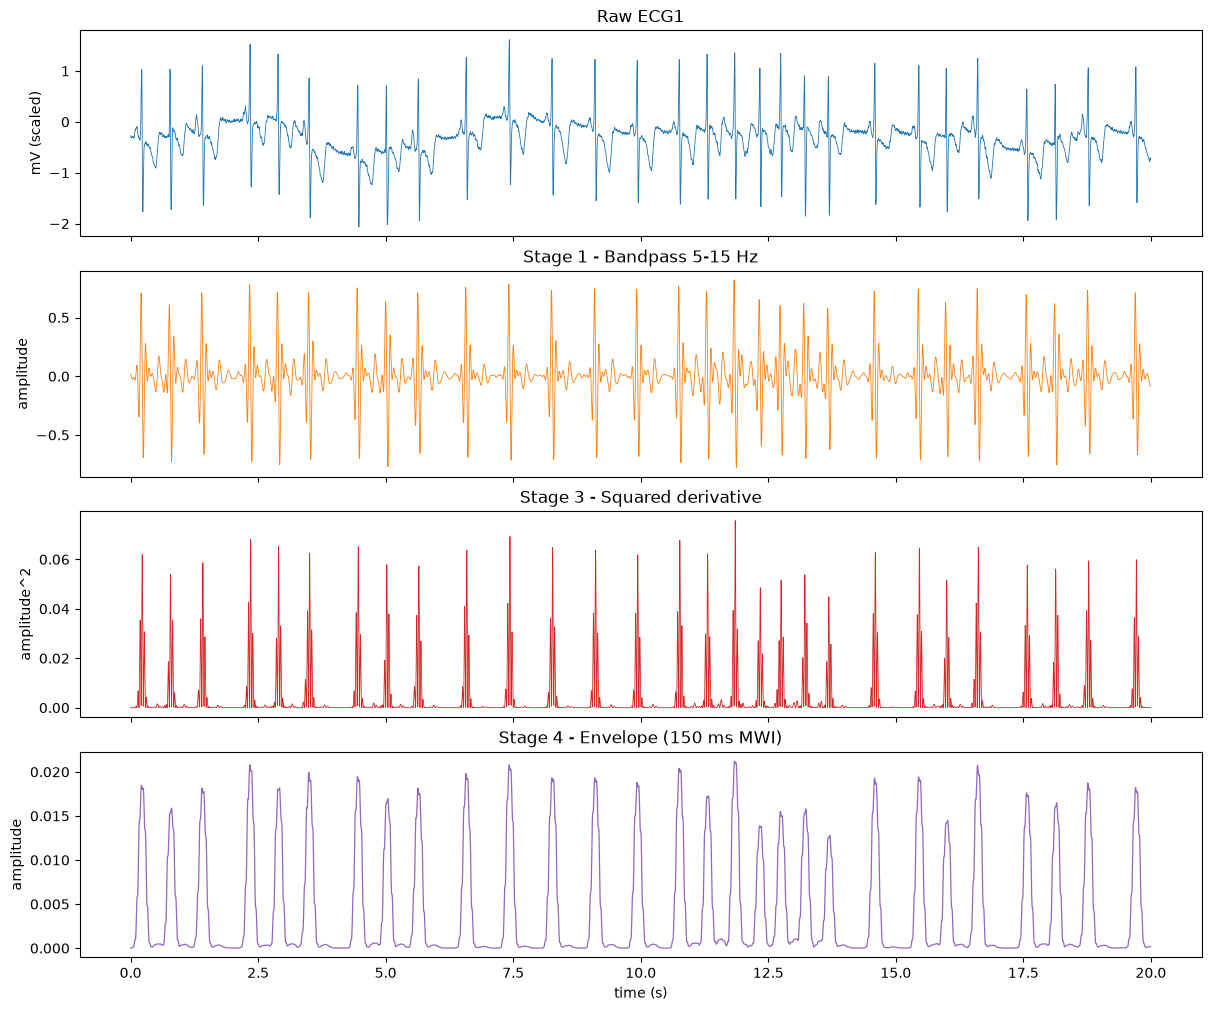

In [13]:
fig, ax = plt.subplots(4, 1, figsize=(12, 10), sharex=True, constrained_layout=True)
ax[0].plot(t, ecg_raw[SLICE],  lw=0.6, color='C0'); ax[0].set_title('Raw ECG1');                       ax[0].set_ylabel('mV (scaled)')
ax[1].plot(t, ecg_filt[SLICE], lw=0.6, color='C1'); ax[1].set_title('Stage 1 - Bandpass 5-15 Hz');      ax[1].set_ylabel('amplitude')
ax[2].plot(t, ecg_sq[SLICE],   lw=0.6, color='C3'); ax[2].set_title('Stage 3 - Squared derivative');    ax[2].set_ylabel('amplitude^2')
ax[3].plot(t, ecg_env[SLICE],  lw=0.9, color='C4'); ax[3].set_title('Stage 4 - Envelope (150 ms MWI)'); ax[3].set_ylabel('amplitude')
ax[3].set_xlabel('time (s)')
plt.show()


## Stage 5 - Adaptive-threshold R-peak detection (Pan-Tompkins)

The detector runs on the stage-4 envelope and uses Pan-Tompkins adaptive
thresholds:

```
SPKI = 0.125 * peak + 0.875 * SPKI     # signal running average
NPKI = 0.125 * peak + 0.875 * NPKI     # noise  running average
T1   = NPKI + 0.25 * (SPKI - NPKI)     # primary threshold
T2   = 0.5 * T1                         # secondary (search-back) threshold
```

Plus a 200 ms refractory (enforced via `scipy.signal.find_peaks`'s
`distance` argument) and a search-back at `1.66 x mean RR` when a beat
looks like it was missed.


In [20]:
def detect_r_peaks(envelope, fs=FS,
                   refractory_sec=REFRACTORY_SEC,
                   search_back_factor=SEARCH_BACK_F,
                   spki_alpha=0.125, npki_alpha=0.125,
                   t1_factor=0.25, t2_factor=0.50):
    """Detect R-peak sample indices on the QRS envelope (note 31, stage 5).

    Parameters
    ----------
    envelope : float ndarray, output of moving_window_integrator
    fs, refractory_sec, search_back_factor : see TASK_BRIEF
    spki_alpha, npki_alpha : EMA factors for SPKI / NPKI
    t1_factor, t2_factor   : threshold factors

    Returns
    -------
    peaks : int ndarray, ascending sample indices of R-peaks
    """
    n = len(envelope)
    refractory = max(1, int(refractory_sec * fs))

    # Step 1 - candidate local maxima with refractory enforced.
    candidates, _ = find_peaks(envelope, distance=refractory)
    if candidates.size == 0:
        return np.array([], dtype=int)

    # Seed SPKI / NPKI from the envelope statistics of the first ~5 s.
    seed_n = min(n, int(5.0 * fs))
    seed = envelope[:seed_n]
    spki = float(np.max(seed))
    npki = float(np.mean(seed)) + 1e-9
    t1 = npki + t1_factor * (spki - npki)
    t2 = t2_factor * t1

    # Step 2 - Pan-Tompkins adaptive thresholding on each candidate.
    peaks = []
    rr_recent = []
    last_accepted = -1

    for cand_idx in candidates:
        cand_val = float(envelope[cand_idx])

        if cand_val > t1:
            peaks.append(int(cand_idx))
            spki = spki_alpha * cand_val + (1 - spki_alpha) * spki
            if last_accepted >= 0:
                rr_recent.append(int(cand_idx) - last_accepted)
            last_accepted = int(cand_idx)
        elif cand_val > t2:
            npki = npki_alpha * cand_val + (1 - npki_alpha) * npki
        # else: below T2, ignore

        t1 = npki + t1_factor * (spki - npki)
        t2 = t2_factor * t1

    # Step 3 - search-back for missed beats.
    if len(peaks) >= 2 and rr_recent:
        mean_rr = int(np.mean(rr_recent))
        sb_limit = int(search_back_factor * mean_rr)
        extra = []
        for i in range(1, len(peaks)):
            gap = peaks[i] - peaks[i - 1]
            if gap > sb_limit:
                lo = peaks[i - 1] + refractory
                hi = min(peaks[i], peaks[i - 1] + sb_limit)
                if hi <= lo:
                    continue
                seg = envelope[lo:hi]
                sb_val = float(np.max(seg))
                if sb_val > t2:
                    sb_idx = lo + int(np.argmax(seg))
                    extra.append(sb_idx)
        if extra:
            peaks = sorted(set(peaks) | set(extra))

    return np.array(peaks, dtype=int)


### Quick test on a 60 s slice

Run on the first 60 s first so we can eyeball the detection before
committing to a full-file run.


Slice length       : 15000 samples (1.00 min)
Peaks found        : 88
Implied HR (rough) : 88.0 bpm


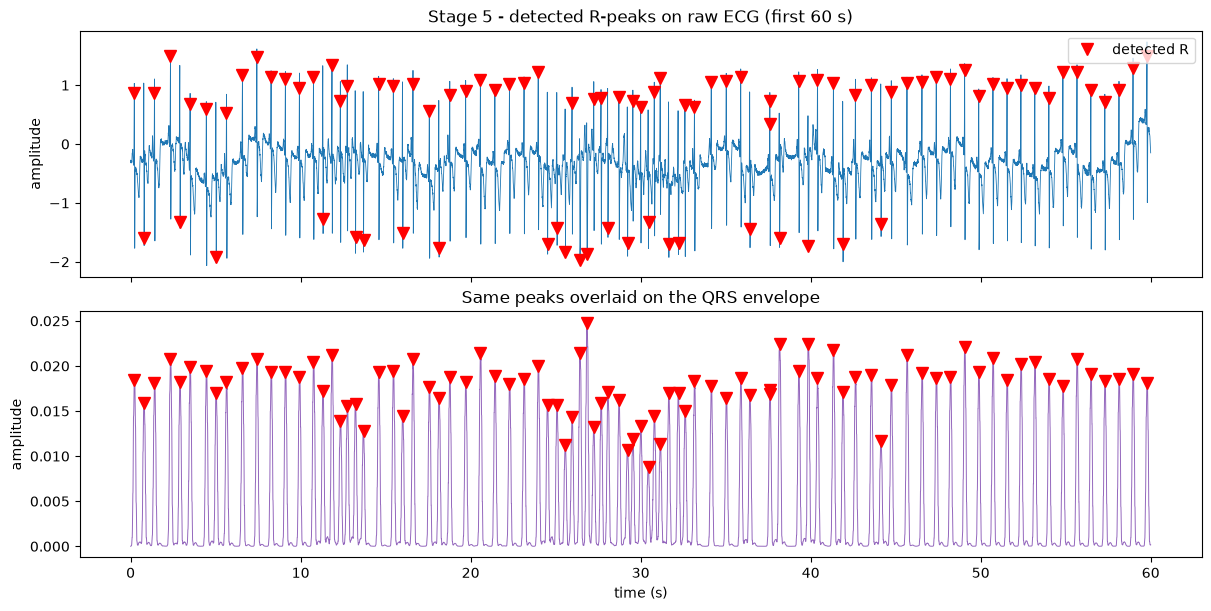

In [21]:
# Quick test on the first 60 s (15 000 samples at 250 Hz)
SLICE_TEST = slice(0, min(15000, len(ecg_env)))
env_test   = ecg_env[SLICE_TEST]
raw_test   = ecg_raw[SLICE_TEST]
peaks_test = detect_r_peaks(env_test, fs=FS)

slice_min = SLICE_TEST.stop / FS / 60.0
print(f"Slice length       : {SLICE_TEST.stop} samples ({slice_min:.2f} min)")
print(f"Peaks found        : {len(peaks_test)}")
print(f"Implied HR (rough) : {len(peaks_test) / max(slice_min, 1e-9):.1f} bpm")

t_test = np.arange(SLICE_TEST.stop) / FS
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True, constrained_layout=True)
ax[0].plot(t_test, raw_test, lw=0.6, color='C0')
ax[0].plot(t_test[peaks_test], raw_test[peaks_test], 'rv', ms=8, label='detected R')
ax[0].set_title('Stage 5 - detected R-peaks on raw ECG (first 60 s)')
ax[0].legend(loc='upper right'); ax[0].set_ylabel('amplitude')

ax[1].plot(t_test, env_test, lw=0.7, color='C4')
ax[1].plot(t_test[peaks_test], env_test[peaks_test], 'rv', ms=8)
ax[1].set_title('Same peaks overlaid on the QRS envelope')
ax[1].set_xlabel('time (s)'); ax[1].set_ylabel('amplitude')
plt.show()


### Zoom: 3 beats

Show ~10 s of ECG with the detected R-peaks marked, so we can confirm
the peaks land on the R-wave rather than on the T-wave.


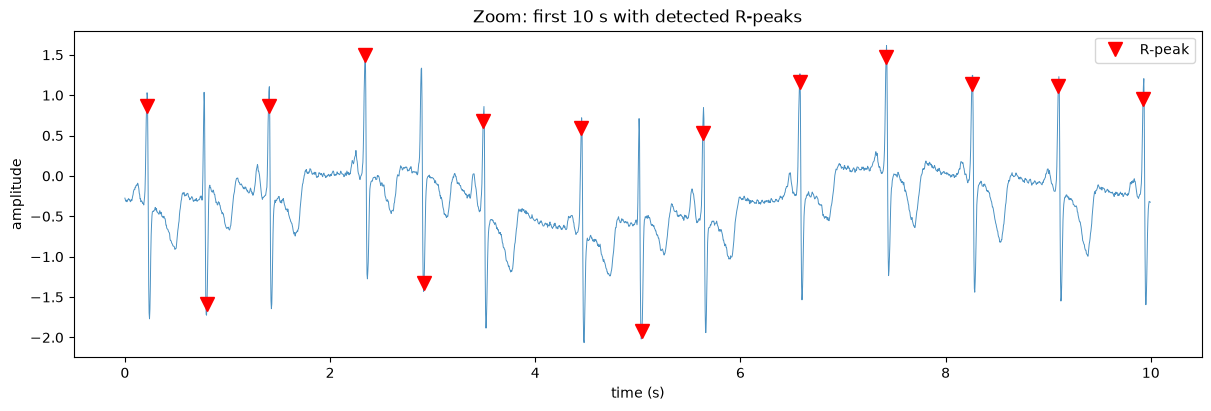

In [22]:
zoom = slice(0, 2500)   # first 10 s
t_zoom = np.arange(zoom.stop) / FS
peaks_zoom = peaks_test[peaks_test < zoom.stop]

fig, ax = plt.subplots(1, 1, figsize=(12, 4), constrained_layout=True)
ax.plot(t_zoom, raw_test[zoom], lw=0.7, color='C0', alpha=0.8)
ax.plot(t_zoom[peaks_zoom], raw_test[peaks_zoom], 'rv', ms=10, label='R-peak')
ax.set_title('Zoom: first 10 s with detected R-peaks')
ax.set_xlabel('time (s)'); ax.set_ylabel('amplitude')
ax.legend(loc='upper right')
plt.show()


### Run on the full file

The file is ~9.2 M samples (~10 h at 250 Hz). The pipeline is O(N) per
stage, so the full run should still complete in a few seconds.


In [23]:
peaks_full = detect_r_peaks(ecg_env, fs=FS)
print(f"Total R-peaks detected : {len(peaks_full):,}")

duration_min = len(ecg_raw) / FS / 60.0
print(f"Recording length        : {duration_min:.1f} min ({duration_min/60:.2f} h)")
print(f"Mean HR over recording  : {len(peaks_full) / max(duration_min, 1e-9):.1f} bpm")


Total R-peaks detected : 600
Recording length        : 613.7 min (10.23 h)
Mean HR over recording  : 1.0 bpm


## RR intervals and heart rate

Stage 6 in TASK_BRIEF: RR series in **sample counts**, not in seconds.


RR (samples): mean=14828.8  std=142732.1  min=50  max=1966205
RR (ms)     : mean=59315.0  std=570928.3
HR (bpm)    : mean=94.2  std=54.0  min=0.0  max=300.0


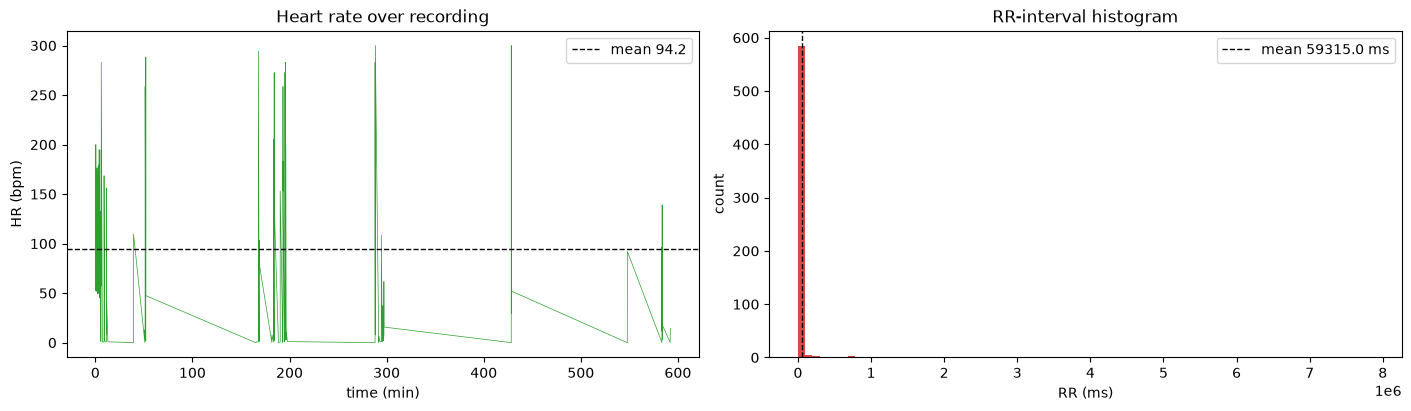

In [24]:
# RR in samples and ms (note 31 says: count samples, not seconds)
rr_samples = np.diff(peaks_full)
rr_ms      = rr_samples / FS * 1000.0
hr_bpm     = FS / rr_samples * 60.0

print(f"RR (samples): mean={rr_samples.mean():.1f}  std={rr_samples.std():.1f}  "
      f"min={rr_samples.min()}  max={rr_samples.max()}")
print(f"RR (ms)     : mean={rr_ms.mean():.1f}  std={rr_ms.std():.1f}")
print(f"HR (bpm)    : mean={hr_bpm.mean():.1f}  std={hr_bpm.std():.1f}  "
      f"min={hr_bpm.min():.1f}  max={hr_bpm.max():.1f}")

# Plot HR trend and RR histogram
t_rr = peaks_full[1:] / FS / 60.0   # minutes from start

fig, ax = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
ax[0].plot(t_rr, hr_bpm, lw=0.5, color='C2')
ax[0].axhline(hr_bpm.mean(), color='k', ls='--', lw=1, label=f"mean {hr_bpm.mean():.1f}")
ax[0].set_title('Heart rate over recording')
ax[0].set_xlabel('time (min)'); ax[0].set_ylabel('HR (bpm)')
ax[0].legend()

ax[1].hist(rr_ms, bins=80, color='C3', alpha=0.85)
ax[1].axvline(rr_ms.mean(), color='k', ls='--', lw=1, label=f"mean {rr_ms.mean():.1f} ms")
ax[1].set_title('RR-interval histogram')
ax[1].set_xlabel('RR (ms)'); ax[1].set_ylabel('count')
ax[1].legend()
plt.show()


## Optional - compare against the `qrs_annotation` column

The CSV ships a `qrs_annotation` column. If it has values, we can use it
to compute sensitivity / FPR for the detector on this record.


In [26]:
ann = read_file['qrs_annotation'].dropna()
print(f"qrs_annotation non-null rows : {len(ann):,}")
print(f"detected R-peaks             : {len(peaks_full):,}")
if len(ann) > 0:
    # Try to coerce annotation values into sample indices
    try:
        ann_idx = ann.to_numpy(dtype=int)
    except Exception:
        # If the annotation is a string of beat numbers, fall back to
        # comparing counts only.
        ann_idx = None

    if ann_idx is not None:
        # Match each annotation to its nearest detected peak within 50 ms
        tolerance = int(0.050 * FS)
        matched = 0
        for a in ann_idx:
            if np.min(np.abs(peaks_full - a)) <= tolerance:
                matched += 1
        sens = matched / len(ann_idx) * 100
        print(f"Matched (within +/-50 ms): {matched}/{len(ann_idx)}  ({sens:.1f}%)")


qrs_annotation non-null rows : 44,005
detected R-peaks             : 600


## Next steps (per TASK_BRIEF)

1. **Stage 6 - RR series** is already produced above as `rr_samples`.
2. **Stage 7 - Features** (RMSSD, normalised RMSSD, pNN50, normalised
   Shannon entropy) over a rolling window. Note the two traps in the
   brief:
   - RMSSD must be normalised by the mean RR before any threshold sees it.
   - Entropy uses a 16-bin histogram of RR values after dropping the 8
     longest and 8 shortest, divided by `log2(16)`.
3. **Stage 8 - Classifier** with two thresholds, AND logic, three
   classes (AF / normal / undecided).
4. **Stage 9 - Confidence** = `min over features of abs(f - threshold) / sigma`.
5. **Stage 10 - Fixed-point mirror** in the int16 12-bit format the RTL uses.

Recommended next cell: split records into train / test before tuning any
threshold (trap #3 in TASK_BRIEF).
